# K-Means Implementation

#### TASK:

1. Implement the K-Means algorithm from scratch
Do not use library implementations of the core algorithm (e.g., sklearn.cluster.KMeans) — you may use libraries like NumPy for numerical operations. 
Your implementation must include:
- Random initialization of centroids. 
- Assignment of each data point to its nearest centroid
- Update of centroid positions based on assigned points
- A stopping criterion (e.g.,centroid movement below a threshold, or a maximum number of iterations).

2. Apply your implementation to the Iris dataset
Run your K-Means implementation on the Iris dataset (use only the feature columns, not the class labels, for clustering).

3. Test multiple values of k
Run your algorithm with at least three different values of k (e.g., k = 2, 3, 4, 5). For each value of k:
Visualize the resulting clusters (e.g., scatter plot using two features or a dimensionality reduction technique such as PCA)

4. Discuss the effect of k:

    In a short written discussion, address:
    - How does the choice of k affect the clustering results?
    - Which value of k seems most appropriate for the Iris dataset, and why?
    - How does this relate to the known number of classes in the Iris dataset?

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA #??
import seaborn as sns


dataset = load_iris() 
Y = dataset.data

# distance calculation, with O(n^2) time complexity
def Distance(Set1, Set2):
    dist = np.zeros((len(Set1), len(Set2)))
    for i in range(len(Set1)):
        for j in range(len(Set2)):
            diff = Set1[i] - Set2[j]
            dist[i, j] = np.sqrt(np.sum(diff**2))
    return dist


def KMeans(points, k, max_iterations=1000, tolerance=10**(-4)):

    data_points = np.asarray(points, dtype=float) # ensure that data is converted to numpy arrays
    nr_data_points = points.shape[0];
    
    current_iteration = 0
    converged = False
    
    if k <= 0:
        raise ValueError('k cannot be equal to or less than zero!!')
    if k > nr_data_points:
        raise ValueError('k cannot be greater than the number of data points!')
    
    randgen = np.random.default_rng(42)
    random_index = randgen.choice(nr_data_points, k) # choose random index values from the dataset itself
    centroids = data_points[random_index].copy()
    
    while converged != True and current_iteration < max_iterations:
        distance = Distance(data_points, centroids)        
        labels = np.argmin(distance, axis=1) # finds the smallest distance

        new_centroids = centroids.copy()
        
        # update centroids
        for cluster_index in range(k):
            cluster_points = points[labels == cluster_index]

            if len(cluster_points) > 0:
                new_centroids[cluster_index] = cluster_points.mean(axis=0) # if empty, keep this centroid at its previous position.
        
        # check convergence
        movements = np.linalg.norm(new_centroids - centroids, axis=1)
        converged = np.max(movements) < tolerance
        
        centroids = new_centroids
        current_iteration += 1
        
    #double check distances
    final_distances = Distance(data_points, centroids)
    final_labels = np.argmin(final_distances, axis=1)
    inertia = np.sum((data_points-centroids[final_labels])**2)
    
    return final_labels, centroids, inertia

## Test set and visualization, with k = 2, 4, 6, 8, and 10

In [10]:
result = {}
intervals = [2, 4, 6, 8, 10]

for g in intervals:
    labels, centroids, inertia = KMeans(Y, k=g)
    result[g] = {
        "labels": labels,
        "centroids": centroids,
        "inertia": inertia
    }
    print({g}, "labels: ", label)
    print("centroids: ", centroids)
    print("inertia: ", inertia)


{2} labels:  [8 6 6 6 8 9 6 8 0 6 9 6 6 0 9 9 9 8 9 8 8 8 6 8 8 6 8 8 8 6 6 8 9 9 6 6 8
 8 0 8 8 0 0 8 8 6 8 6 8 6 3 3 3 4 3 4 3 2 3 4 2 4 4 3 4 3 4 4 3 4 5 4 5 3
 3 3 3 3 3 4 4 4 4 5 4 3 3 3 4 4 4 3 4 2 4 4 4 3 2 4 1 5 7 1 1 7 4 7 1 7 1
 5 1 5 5 1 1 7 7 5 1 5 7 5 1 7 5 5 1 7 7 7 1 5 5 7 1 1 5 1 1 1 5 1 1 1 5 1
 1 5]
centroids:  [[5.00566038 3.36981132 1.56037736 0.29056604]
 [6.30103093 2.88659794 4.95876289 1.69587629]]
inertia:  152.34795176035792
{4} labels:  [8 6 6 6 8 9 6 8 0 6 9 6 6 0 9 9 9 8 9 8 8 8 6 8 8 6 8 8 8 6 6 8 9 9 6 6 8
 8 0 8 8 0 0 8 8 6 8 6 8 6 3 3 3 4 3 4 3 2 3 4 2 4 4 3 4 3 4 4 3 4 5 4 5 3
 3 3 3 3 3 4 4 4 4 5 4 3 3 3 4 4 4 3 4 2 4 4 4 3 2 4 1 5 7 1 1 7 4 7 1 7 1
 5 1 5 5 1 1 7 7 5 1 5 7 5 1 7 5 5 1 7 7 7 1 5 5 7 1 1 5 1 1 1 5 1 1 1 5 1
 1 5]
centroids:  [[5.006      3.428      1.462      0.246     ]
 [6.9125     3.1        5.846875   2.13125   ]
 [5.52962963 2.62222222 3.94074074 1.21851852]
 [6.23658537 2.85853659 4.80731707 1.62195122]]
inertia:  57.256009315718

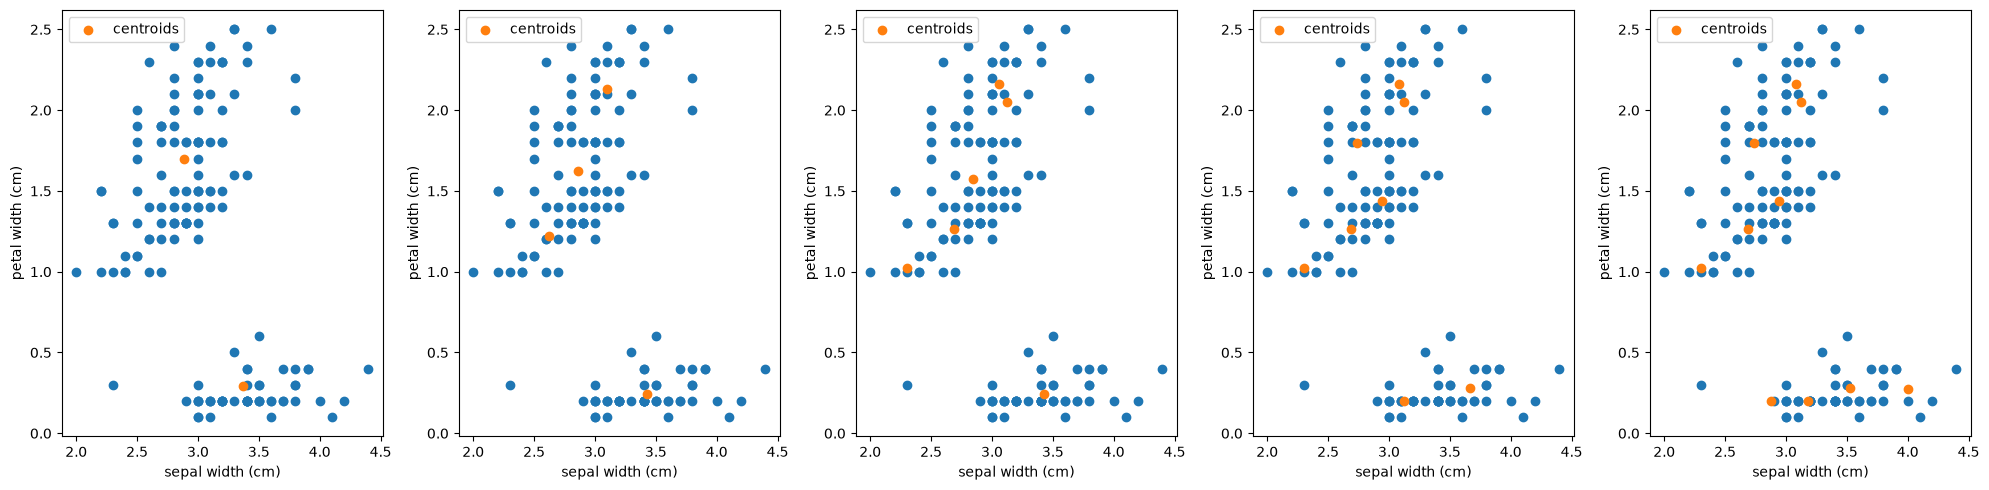

In [29]:
fig, axs = plt.subplots(1, 5, figsize=(20,5))

x_feat = 1 # sepal width
y_feat = 3 # petal width

feat1 = dataset.feature_names[x_feat]
feat2 = dataset.feature_names[y_feat]

for axis, k_val in zip(axs, intervals):
    labels, centroids, inertia = KMeans(Y, k_val)

    axis.scatter(Y[:, x_feat], Y[:, y_feat])
    axis.scatter(centroids[:, x_feat], centroids[:, y_feat], label="centroids")
    axis.set_xlabel(feat1)
    axis.set_ylabel(feat2)
    axis.legend()

plt.tight_layout()
plt.show()